#  Esse notebook contém os códigos para toda a parte exploratória do trabalho

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_final = pd.read_csv('Dados_IBGE (2).csv')

###Histograma e Boxplot da Variável Resposta

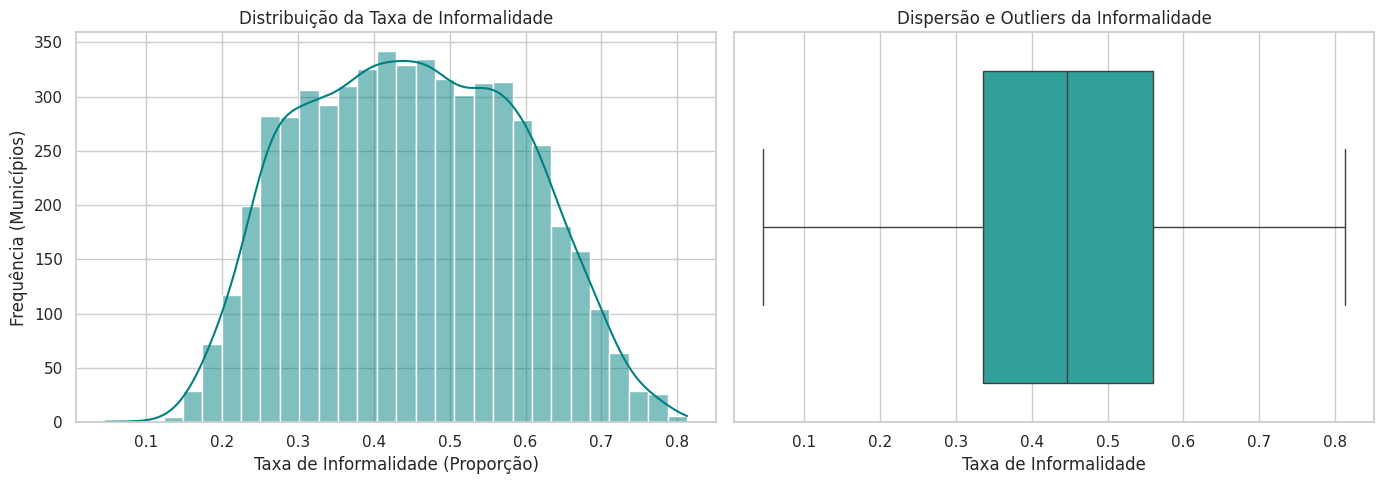

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 12})

fig1, axes1 = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_final, x='Taxa_Informalidade', bins=30, kde=True, color='teal', ax=axes1[0])
axes1[0].set_title('Distribuição da Taxa de Informalidade')
axes1[0].set_xlabel('Taxa de Informalidade (Proporção)')
axes1[0].set_ylabel('Frequência (Municípios)')

sns.boxplot(data=df_final, x='Taxa_Informalidade', color='lightseagreen', ax=axes1[1])
axes1[1].set_title('Dispersão e Outliers da Informalidade')
axes1[1].set_xlabel('Taxa de Informalidade')

plt.tight_layout()
plt.savefig('distribuicao_informalidade.png')
plt.show()

### V.A. Resposta vs. V.A. Preditora

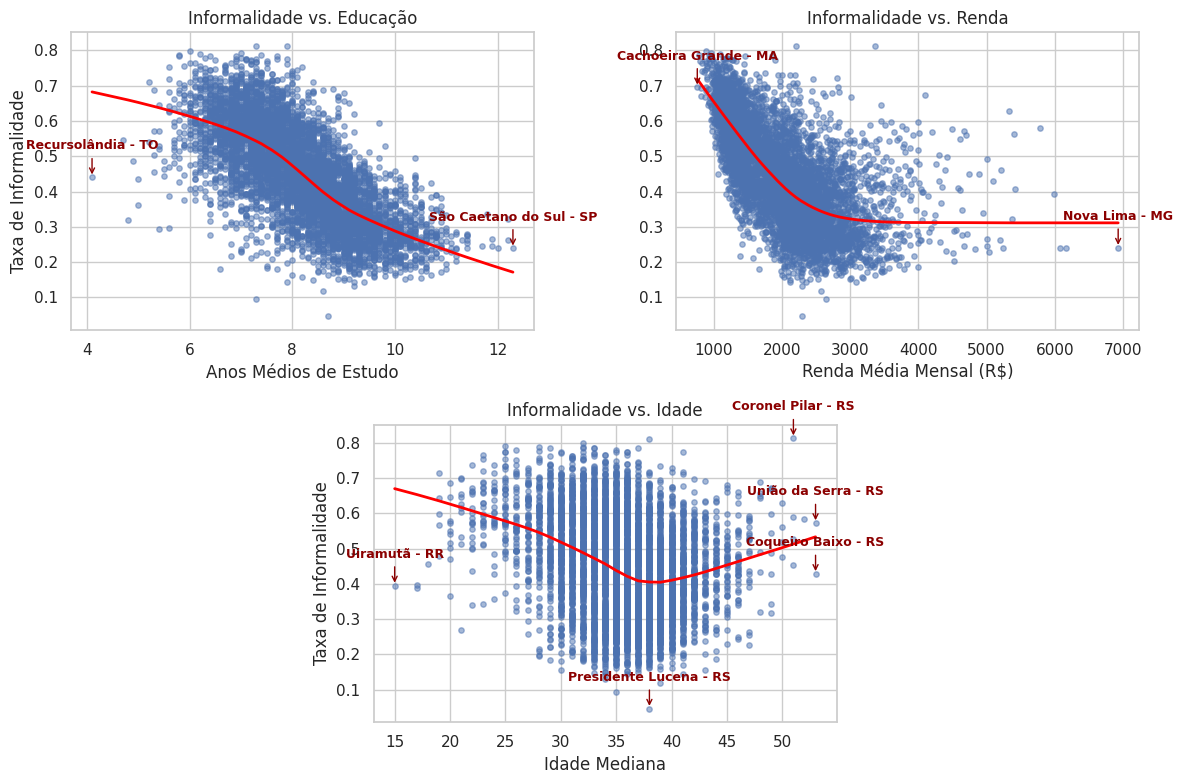

In [ ]:
import matplotlib.gridspec as gridspec

fig2 = plt.figure(figsize=(12, 8))
gs = gridspec.GridSpec(2, 4)

ax1 = fig2.add_subplot(gs[0, 0:2])
ax2 = fig2.add_subplot(gs[0, 2:4])
ax3 = fig2.add_subplot(gs[1, 1:3])

scatter_kws = {'alpha': 0.5, 's': 15}
line_kws = {'color': 'red', 'linewidth': 2}

#Estudo
sns.regplot(data=df_final, x='Anos_Estudo_Medio', y='Taxa_Informalidade',
            lowess=True, scatter_kws=scatter_kws, line_kws=line_kws, ax=ax1)
ax1.set_title('Informalidade vs. Educação')
ax1.set_xlabel('Anos Médios de Estudo')
ax1.set_ylabel('Taxa de Informalidade')

condicao_1 = (df_final['Anos_Estudo_Medio'] > 12.2)
condicao_2 = (df_final['Anos_Estudo_Medio'] < 4.2)
marca = df_final[condicao_1 | condicao_2]

for index, row in marca.iterrows():
    ax1.annotate(
        row['Nome_Municipio'],
        (row['Anos_Estudo_Medio'], row['Taxa_Informalidade']),
        textcoords="offset points",
        xytext=(0, 20),
        ha='center',
        fontsize=9,
        color='darkred',
        weight='bold',
        arrowprops=dict(arrowstyle="->", color='darkred', lw=1)
    )

#Renda
sns.regplot(data=df_final, x='Renda_Media_Mensal', y='Taxa_Informalidade',
            lowess=True, scatter_kws=scatter_kws, line_kws=line_kws, ax=ax2)
ax2.set_title('Informalidade vs. Renda')
ax2.set_xlabel('Renda Média Mensal (R$)')
ax2.set_ylabel('')

condicao_1 = (df_final['Renda_Media_Mensal'] > 6500)
condicao_2 = (df_final['Renda_Media_Mensal'] < 770)
marca = df_final[condicao_1 | condicao_2]

for index, row in marca.iterrows():
    ax2.annotate(
        row['Nome_Municipio'],
        (row['Renda_Media_Mensal'], row['Taxa_Informalidade']),
        textcoords="offset points",
        xytext=(0, 20),
        ha='center',
        fontsize=9,
        color='darkred',
        weight='bold',
        arrowprops=dict(arrowstyle="->", color='darkred', lw=1)
    )

sns.regplot(data=df_final, x='Idade_Mediana', y='Taxa_Informalidade',
            lowess=True, scatter_kws=scatter_kws, line_kws=line_kws, ax=ax3)
ax3.set_title('Informalidade vs. Idade')
ax3.set_xlabel('Idade Mediana')
ax3.set_ylabel('Taxa de Informalidade')


#Idade
condicao_1 = (df_final['Idade_Mediana'] > 52)
condicao_2 = (df_final['Idade_Mediana'] < 15.2)
condicao_3 = (df_final['Taxa_Informalidade'] > 0.812)
condicao_4 = (df_final['Taxa_Informalidade'] < 0.08)
marca = df_final[condicao_1 | condicao_2 | condicao_3 | condicao_4]

for index, row in marca.iterrows():
    ax3.annotate(
        row['Nome_Municipio'],
        (row['Idade_Mediana'], row['Taxa_Informalidade']),
        textcoords="offset points",
        xytext=(0, 20),
        ha='center',
        fontsize=9,
        color='darkred',
        weight='bold',
        arrowprops=dict(arrowstyle="->", color='darkred', lw=1)
    )

plt.tight_layout()
plt.savefig('graficos_exploratorios.png')
plt.show()


### Tabela Descritiva

In [ ]:
cols = ['Taxa_Informalidade', 'Anos_Estudo_Medio', 'Renda_Media_Mensal', 'Idade_Mediana']
tabela_descritiva = df_final[cols].agg(
    ['mean', 'median', 'std', 'min', 'max', 'skew']
).T

tabela_descritiva.columns = ['Média', 'Mediana', 'Desvio Padrão', 'Mínimo', 'Máximo', 'Assimetria']
tabela_descritiva = tabela_descritiva.round(3)

tabela_descritiva

,Média,Mediana,Desvio Padrão,Mínimo,Máximo,Assimetria
Taxa_Informalidade,0.449,0.446,0.139,0.046,0.813,0.074
Anos_Estudo_Medio,8.161,8.100,1.112,4.100,12.300,0.198
Renda_Media_Mensal,2010.289,1954.985,696.271,758.510,6929.480,1.018
Idade_Mediana,35.410,36.000,4.505,15.000,53.000,-0.234


### Matriz de correlação

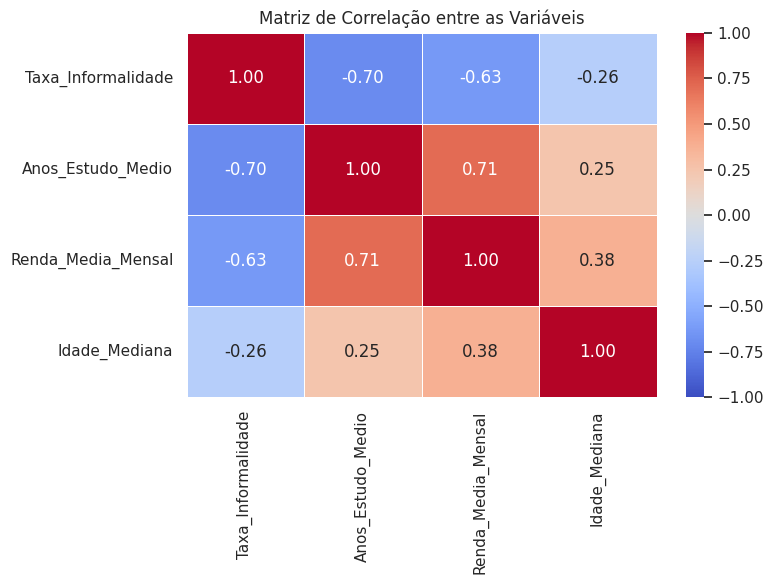

In [ ]:
matriz_corr = df_final[cols].corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlação entre as Variáveis')
plt.tight_layout()
plt.savefig('matriz_correlacao.png')
plt.show()

### Mapa de Calor

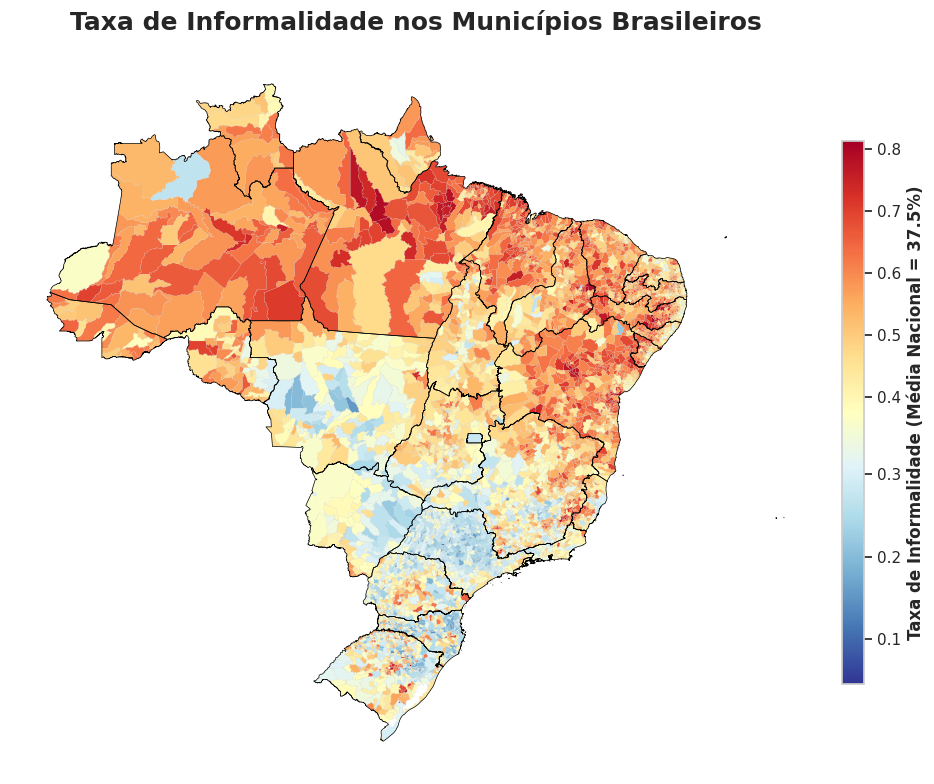

In [ ]:
import geobr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

df = df_final.copy()
df["Cod_Municipio"] = df["Cod_Municipio"].astype(int)

geo_municipios = geobr.read_municipality(year=2022)
geo_municipios["code_muni"] = geo_municipios["code_muni"].astype(int)

mapa_data = geo_municipios.merge(
    df, left_on="code_muni", right_on="Cod_Municipio", how="inner"
)

geo_estados = geobr.read_state(year=2022)

norm = TwoSlopeNorm(
    vmin=mapa_data["Taxa_Informalidade"].min(),
    vcenter=0.375,
    vmax=mapa_data["Taxa_Informalidade"].max(),
)

fig, ax = plt.subplots(1, 1, figsize=(11, 8))

im = mapa_data.plot(
    column="Taxa_Informalidade",
    cmap="RdYlBu_r",
    norm=norm,
    linewidth=0.08,
    ax=ax,
    edgecolor="0.8",
    legend=False,
)

geo_estados.plot(ax=ax, color="none", edgecolor="black", linewidth=0.5)

ax.set_title(
    "Taxa de Informalidade nos Municípios Brasileiros",
    fontsize=18,
    fontweight="bold",
    pad=15,
)
ax.set_axis_off()


sm = plt.cm.ScalarMappable(cmap="RdYlBu_r", norm=norm)
sm._A = []
cbar = fig.colorbar(
    sm, ax=ax, orientation="vertical", shrink=0.75, pad=0.02, aspect=25
)
cbar.set_label(
    "Taxa de Informalidade (Média Nacional = 37.5%)", fontsize=12, fontweight="bold"
)

plt.tight_layout()
plt.savefig("mapa_informalidade_brasil.png", dpi=300, bbox_inches="tight")
plt.show()

### Ajuste não definitivo

Apenas para verificar a premissa da Binomial e justificar a Quase-binomial

In [ ]:
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

df = df_final.copy()
df["Cod_Municipio"] = df["Cod_Municipio"].astype(int)

formula = (
    "Taxa_Informalidade ~ Anos_Estudo_Medio + Renda_Media_Mensal + Idade_Mediana"
)

modelo_binomial = smf.glm(
    formula=formula,
    data=df,
    family=sm.families.Binomial(),
    var_weights=df[
        "Total_Ocupados"
    ],
).fit()

deviance_residual = modelo_binomial.deviance
graus_de_liberdade = modelo_binomial.df_resid
phi_hat = deviance_residual / graus_de_liberdade

print(f"Deviance Residual: {deviance_residual:.4f}")
print(f"Graus de Liberdade Residuais: {graus_de_liberdade}")
print(f"Parâmetro de Dispersão Estimado com pesos (phi): {phi_hat:.4f}")

Deviance Residual: 2163215.9581
Graus de Liberdade Residuais: 5566
Parâmetro de Dispersão Estimado com pesos (phi): 388.6482
